In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_excel("Cleaned_Sales_Dataset.xlsx")
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Year,Month,Month_Name
0,ORD100002,2025-02-25,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,2025,2,February
1,ORD100003,2025-10-14,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,2025,10,October
2,ORD100004,2025-05-13,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,2025,5,May
3,ORD100005,2025-12-02,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,2025,12,December
4,ORD100006,2025-11-20,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,2025,11,November


In [3]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age',
       'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price',
       'Total_Sales', 'Year', 'Month', 'Month_Name'],
      dtype='object')

In [4]:
df.shape

(1000, 15)

In [5]:
total_sales = df['Total_Sales'].sum()
total_orders = df['Order_ID'].nunique()
total_quantity = df['Quantity'].sum()
total_customers = df['Customer_ID'].nunique()
average_order_value = total_sales / total_orders
print("Total Sales:", total_sales)
print("Total Orders:", total_orders)
print("Total Quantity:", total_quantity)
print("Total Customers:", total_customers)
print("Average Order Value:", average_order_value)

Total Sales: 139399439.65
Total Orders: 992
Total Quantity: 5435
Total Customers: 947
Average Order Value: 140523.6286794355


## 1. Core KPIs
### 1. Total Sales
**Formula:** Total Sales = Σ(Total_Sales)
**Business Rationale:** Measures the overall sales generated during the analyzed period.
### 2. Total Orders
**Formula:** Total Orders = COUNT(DISTINCT Order_ID)
**Business Rationale:** Measures the number of unique orders placed by customers.
### 3. Total Quantity
**Formula:** Total Quantity = Σ(Quantity)
**Business Rationale:** Shows the total number of products sold.
### 4. Total Customers
**Formula:** Total Customers = COUNT(DISTINCT Customer_ID)
**Business Rationale:** Measures the number of unique customers in the dataset.
### 5. Average Order Value
**Formula:** Average Order Value = Total Sales / Total Orders
**Business Rationale:** Shows the average sales value generated per order.

In [6]:
customer_data = df.groupby(
    ['Customer_ID', 'Customer_Name']
).agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order_ID', 'nunique')
).reset_index()
customer_data.head()

,Customer_ID,Customer_Name,Total_Sales,Total_Quantity,Total_Orders
0,CUST1004,Customer_191,8321.54,2,1
1,CUST1017,Customer_387,264230.68,7,1
2,CUST1026,Customer_445,164965.29,7,1
3,CUST1032,Customer_20,146990.90,7,1
4,CUST1038,Customer_454,37068.40,5,1


In [7]:
print("Total unique customers:", customer_data['Customer_ID'].nunique())
print("Customer-level rows:", len(customer_data))

Total unique customers: 947
Customer-level rows: 1000


In [8]:
customer_data[['Total_Sales', 'Total_Quantity', 'Total_Orders']].describe()

,Total_Sales,Total_Quantity,Total_Orders
count,1000.000000,1000.000000,1000.0
mean,139399.439650,5.435000,1.0
std,114100.051546,2.838632,0.0
min,437.340000,1.000000,1.0
25%,47066.632500,3.000000,1.0
50%,108594.025000,5.000000,1.0
75%,203722.882500,8.000000,1.0
max,493677.500000,10.000000,1.0


In [9]:
def assign_segment(sales):
    if sales >= 200000:
        return "High Value"
    elif sales >= 75000:
        return "Medium Value"
    else:
        return "Low Value"
customer_data['Customer_Segment'] = customer_data['Total_Sales'].apply(assign_segment)
customer_data.head()

,Customer_ID,Customer_Name,Total_Sales,Total_Quantity,Total_Orders,Customer_Segment
0,CUST1004,Customer_191,8321.54,2,1,Low Value
1,CUST1017,Customer_387,264230.68,7,1,High Value
2,CUST1026,Customer_445,164965.29,7,1,Medium Value
3,CUST1032,Customer_20,146990.90,7,1,Medium Value
4,CUST1038,Customer_454,37068.40,5,1,Low Value


In [10]:
segment_counts = customer_data['Customer_Segment'].value_counts()
print(segment_counts)

Customer_Segment
Medium Value    383
Low Value       356
High Value      261
Name: count, dtype: int64


In [11]:
segment_sales = customer_data.groupby('Customer_Segment')['Total_Sales'].sum().sort_values(ascending=False)
print(segment_sales)

Customer_Segment
High Value      78436938.04
Medium Value    48927595.76
Low Value       12034905.85
Name: Total_Sales, dtype: float64


In [12]:
segment_sales_percentage = (
    segment_sales / segment_sales.sum() * 100
).round(2)
print(segment_sales_percentage)

Customer_Segment
High Value      56.27
Medium Value    35.10
Low Value        8.63
Name: Total_Sales, dtype: float64


In [13]:
high_value_customers = customer_data[
    customer_data['Customer_Segment'] == 'High Value'
]
high_value_ids = high_value_customers['Customer_ID']
high_value_sales = df[
    df['Customer_ID'].isin(high_value_ids)
]
category_sales_high = (
    high_value_sales
    .groupby('Category')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
)
print(category_sales_high)

Category
Electronics    29881604.88
Grocery        14200072.75
Education      14110203.67
Furniture      12494268.58
Fashion        10280172.43
Name: Total_Sales, dtype: float64


In [14]:
city_sales_high = (
    high_value_sales
    .groupby('City')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
)
print(city_sales_high)

City
Bengaluru    11921671.21
Patna        11856340.05
Mumbai       11395673.86
Kolkata      11153373.72
Hyderabad     9875931.31
Delhi         9073480.59
Pune          8698913.39
Gaya          6990938.18
Name: Total_Sales, dtype: float64


In [15]:
product_sales_high = (
    high_value_sales
    .groupby('Product')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(product_sales_high)

Product
Laptop    16097396.57
Rice      14200072.75
Book      14110203.67
Mobile    13784208.31
Chair     12494268.58
Shoes     10280172.43
Name: Total_Sales, dtype: float64


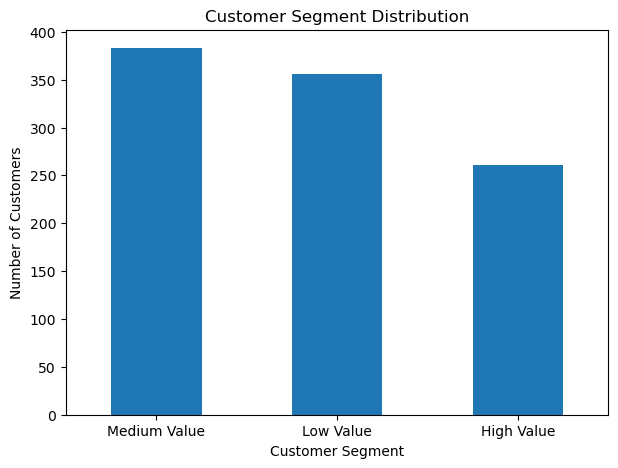

In [16]:
segment_counts.plot(
    kind='bar',
    figsize=(7, 5),
    title='Customer Segment Distribution'
)
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

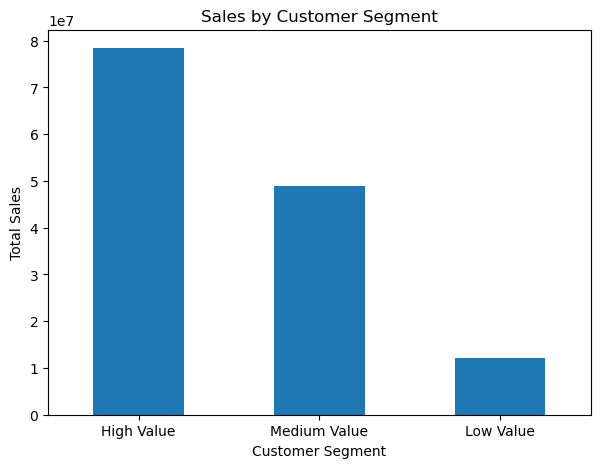

In [17]:
segment_sales.plot(
    kind='bar',
    figsize=(7, 5),
    title='Sales by Customer Segment'
)
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

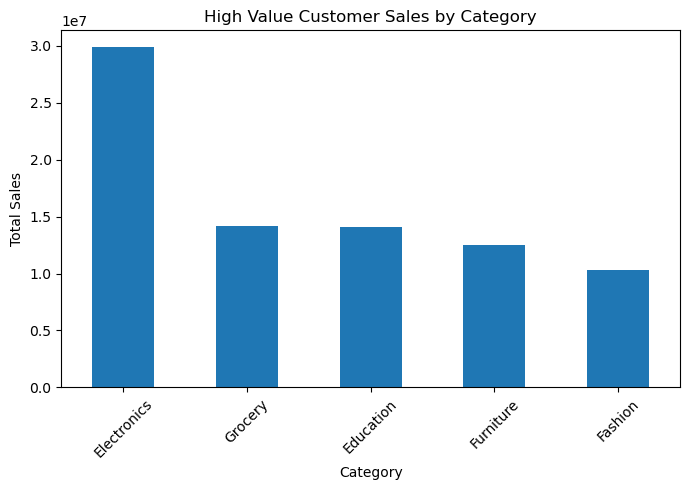

In [18]:
category_sales_high.plot(
    kind='bar',
    figsize=(7, 5),
    title='High Value Customer Sales by Category'
)
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

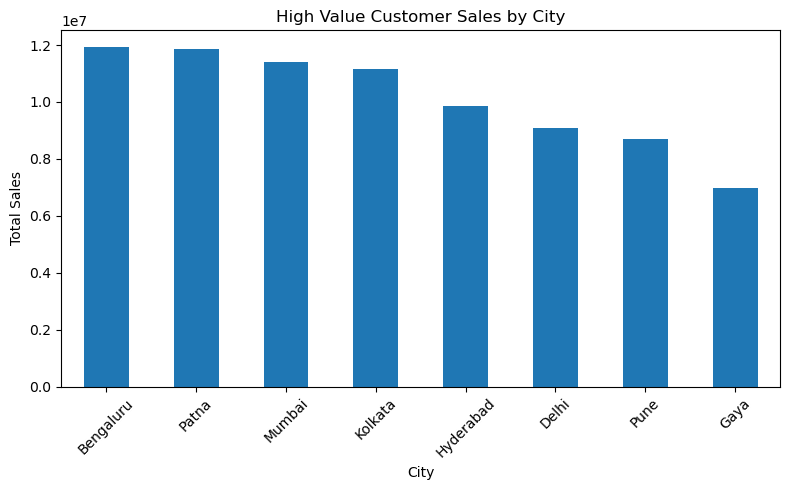

In [19]:
city_sales_high.plot(
    kind='bar',
    figsize=(8, 5),
    title='High Value Customer Sales by City'
)
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

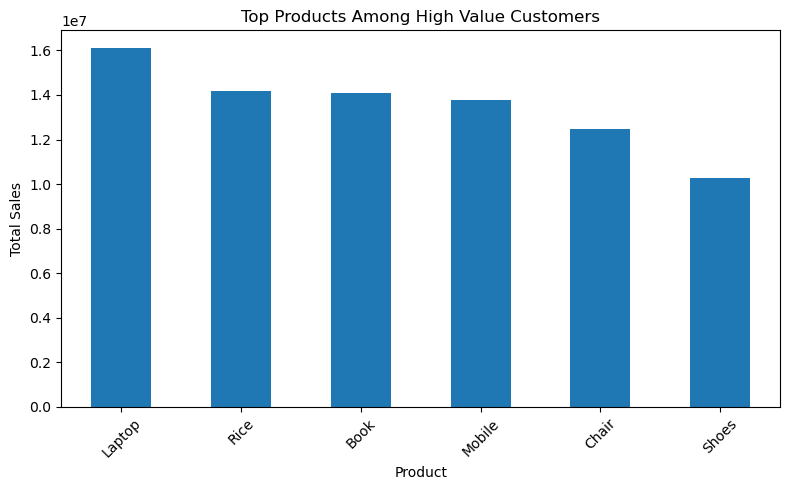

In [20]:
product_sales_high.plot(
    kind='bar',
    figsize=(8, 5),
    title='Top Products Among High Value Customers'
)
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Key Findings
1. High Value customers contribute the largest share of total sales.
2. Electronics is the highest-selling category among High Value customers.
3. Bengaluru records the highest sales from High Value customers.
4. Laptop is the top-selling product among High Value customers.
5. Customer segmentation helps identify high-value customers and understand their purchasing patterns.

In [21]:
customer_data.groupby('Customer_ID')['Customer_Segment'].nunique().value_counts()

Customer_Segment
1    911
2     35
3      1
Name: count, dtype: int64

In [22]:
customer_data = df.groupby('Customer_ID').agg(
    Customer_Name=('Customer_Name', 'first'),
    Total_Sales=('Total_Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Order_ID', 'nunique')
).reset_index()
customer_data.head()

,Customer_ID,Customer_Name,Total_Sales,Total_Quantity,Total_Orders
0,CUST1004,Customer_191,8321.54,2,1
1,CUST1017,Customer_387,264230.68,7,1
2,CUST1026,Customer_445,164965.29,7,1
3,CUST1032,Customer_20,146990.90,7,1
4,CUST1038,Customer_454,37068.40,5,1


In [23]:
print("Unique customers:", customer_data['Customer_ID'].nunique())
print("Customer-level rows:", len(customer_data))

Unique customers: 947
Customer-level rows: 947


In [24]:
def assign_segment(sales):
    if sales >= 200000:
        return "High Value"
    elif sales >= 75000:
        return "Medium Value"
    else:
        return "Low Value"
customer_data['Customer_Segment'] = customer_data['Total_Sales'].apply(assign_segment)
customer_data['Customer_Segment'].value_counts()

Customer_Segment
Medium Value    356
Low Value       327
High Value      264
Name: count, dtype: int64

In [25]:
segment_sales = (
    customer_data
    .groupby('Customer_Segment')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
)
segment_sales

Customer_Segment
High Value      82645541.15
Medium Value    45571882.13
Low Value       11182016.37
Name: Total_Sales, dtype: float64

In [27]:
segment_sales_percentage = (
    segment_sales / segment_sales.sum() * 100
).round(2)
segment_sales_percentage

Customer_Segment
High Value      59.29
Medium Value    32.69
Low Value        8.02
Name: Total_Sales, dtype: float64

## Key Findings
1. High Value customers contribute the largest share of total sales, accounting for 59.29%.
2. High Value customers represent 264 unique customers.
3. Medium Value customers represent 356 unique customers and contribute 32.69% of total sales.
4. Low Value customers represent 327 unique customers and contribute 8.02% of total sales.
5. Customer segmentation helps identify high-value customers and understand their purchasing patterns.

In [28]:
high_value_customers = customer_data[
    customer_data['Customer_Segment'] == 'High Value'
]
high_value_ids = high_value_customers['Customer_ID']
high_value_sales = df[
    df['Customer_ID'].isin(high_value_ids)
]
print("High Value Customers:", len(high_value_customers))
print("High Value Sales Rows:", len(high_value_sales))

High Value Customers: 264
High Value Sales Rows: 299


In [29]:
category_sales_high = (
    high_value_sales
    .groupby('Category')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
)
category_sales_high

Category
Electronics    30521394.90
Grocery        14488085.65
Education      14357513.59
Furniture      12820220.92
Fashion        10458326.09
Name: Total_Sales, dtype: float64

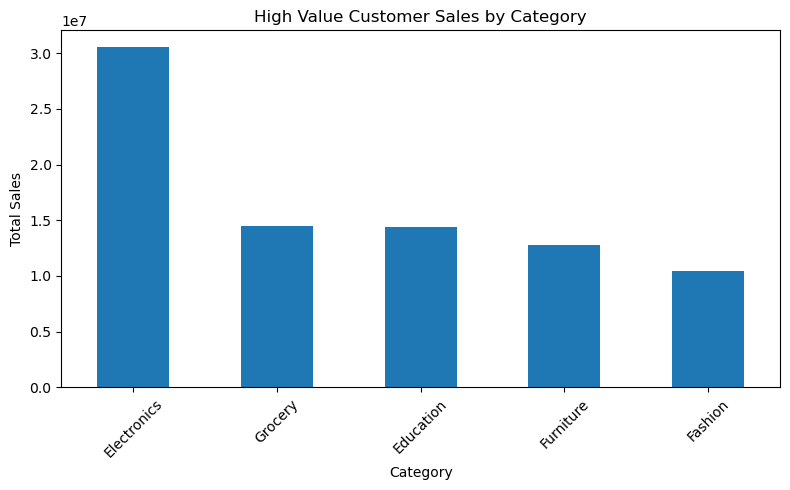

In [30]:
category_sales_high.plot(
    kind='bar',
    figsize=(8, 5),
    title='High Value Customer Sales by Category'
)
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
product_sales_high = (
    high_value_sales
    .groupby('Product')['Total_Sales']
    .sum()
    .sort_values(ascending=False)
)
product_sales_high

Product
Laptop    16419965.93
Rice      14488085.65
Book      14357513.59
Mobile    14101428.97
Chair     12820220.92
Shoes     10458326.09
Name: Total_Sales, dtype: float64

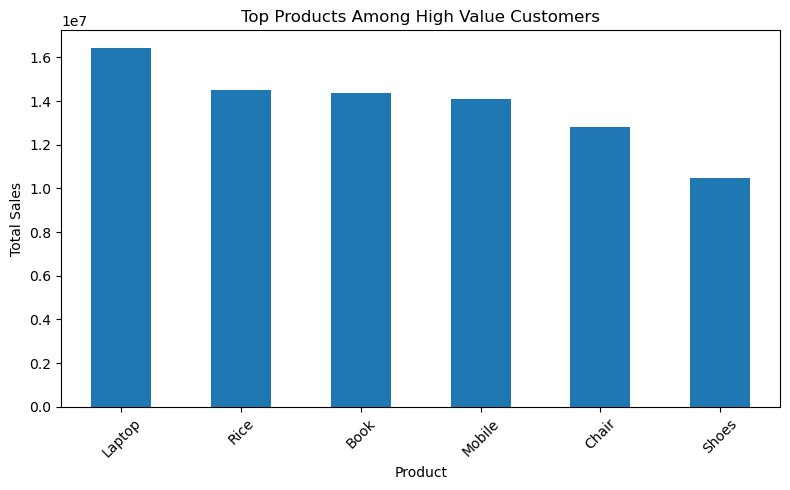

In [32]:
product_sales_high.plot(
    kind='bar',
    figsize=(8, 5),
    title='Top Products Among High Value Customers'
)
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Key Findings
1. The dataset contains 947 unique customers.
2. High Value customers represent 264 customers and contribute 59.29% of total sales.
3. Medium Value customers represent 356 customers and contribute 32.69% of total sales.
4. Low Value customers represent 327 customers and contribute 8.02% of total sales.
5. Electronics is the highest-selling category among High Value customers.
6. Laptop is the top-selling product among High Value customers.
7. Customer segmentation helps identify high-value customers and understand their purchasing patterns.

In [33]:
customer_segment_map = customer_data[
    ['Customer_ID', 'Customer_Segment']
]
df_dashboard = df.merge(
    customer_segment_map,
    on='Customer_ID',
    how='left'
)
df_dashboard.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Year,Month,Month_Name,Customer_Segment
0,ORD100002,2025-02-25,CUST5529,Customer_227,30,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,2025,2,February,Low Value
1,ORD100003,2025-10-14,CUST3127,Customer_182,63,Male,Bengaluru,Book,Education,5,27906.16,139530.80,2025,10,October,Medium Value
2,ORD100004,2025-05-13,CUST8887,Customer_487,62,Female,Bengaluru,Book,Education,8,37491.06,299928.48,2025,5,May,High Value
3,ORD100005,2025-12-02,CUST2515,Customer_470,65,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,2025,12,December,High Value
4,ORD100006,2025-11-20,CUST4796,Customer_380,44,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,2025,11,November,Medium Value


In [34]:
print("Original rows:", len(df))
print("Dashboard rows:", len(df_dashboard))

Original rows: 1000
Dashboard rows: 1000


In [35]:
df_dashboard['Customer_Segment'].value_counts()

Customer_Segment
Medium Value    370
Low Value       331
High Value      299
Name: count, dtype: int64

In [36]:
df_dashboard.to_excel(
    'ApexPlanet_Task_3_Dashboard_Data.xlsx',
    index=False
)

In [37]:
print("Dashboard dataset exported successfully!")

Dashboard dataset exported successfully!
